# Práctica 1 · Detección de fraude con Spark MLlib

**Problema:** clasificar transacciones como normales (`0`) o fraudulentas (`1`).  
**Datos:** `cleaned.csv`, derivado de un conjunto de transacciones financieras utilizado en el notebook original.  
**Objetivo:** comparar varios modelos, ajustar parámetros y medir su calidad en datos que no se han utilizado para entrenarlos.

Este notebook está ordenado **de principio a fin**. Cada apartado explica qué hace el código y qué resultado hay que interpretar.

| Orden | Apartado | ¿Para qué sirve? |
|---|---|---|
| 1 | Configuración | Importar librerías y preparar Spark |
| 2 | Carga de datos | Leer el CSV y localizar la variable objetivo |
| 3 | Calidad de datos | Revisar tipos, nulos y clases |
| 4 | Análisis exploratorio | Entender cómo son las transacciones |
| 5 | Variables y preparación | Prevenir fugas de información y elegir predictores |
| 6 | Entrenamiento | Comparar 3 algoritmos de MLlib |
| 7 | Hiperparámetros | Optimizar regresión logística |
| 8 | Comparación adicional | Comprobar el efecto de usar saldos posteriores |
| 9 | Selección y umbral | Elegir el modelo y cuándo clasificar como fraude |
| 10 | Resultados finales | Evaluar una única vez en test |
| 11 | Interpretación y exportación | Guardar resultados y resumir conclusiones |

> **Importante:** el fichero `cleaned.csv` no está adjunto aquí. Este notebook se ha revisado y reorganizado, pero **no se han recalculado sus métricas**. Se obtendrán al ejecutarlo sobre los datos reales.

## 1. Configuración

Cargamos las librerías y elegimos las rutas de entrada y salida. Spark se encarga del procesamiento grande; **pandas solo se utiliza para tablas pequeñas** y Matplotlib para tres gráficos sencillos.

In [1]:
import os
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import NumericType
from pyspark.storagelevel import StorageLevel
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
from pyspark.ml.functions import vector_to_array

# Cambiar estas opciones si se necesita.
SEED = 42
DATA_PATH = os.environ.get("DATA_PATH", "cleaned.csv")
OUT = Path(os.environ.get("OUTPUT_DIR", "resultados"))
OUT.mkdir(parents=True, exist_ok=True)

# Activar el experimento adicional si interesa comparar variables posteriores.
COMPARAR_SALDOS_POSTERIORES = True
GUARDAR_MODELO = True

spark = (
    SparkSession.builder
    .appName("AAGE_Practica1_Fraude")
    .master("local[2]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Versión de Spark:", spark.version)
print("Directorio de resultados:", OUT.resolve())


Versión de Spark: 3.5.8
Directorio de resultados: C:\Users\murad\OneDrive - Universidade da Coruña\4 Curso\AAGE\AAGE_P1_fraude_pack\resultados


## 2. Carga de datos

Leemos el archivo y comprobamos su tamaño. La columna objetivo indica si una transacción fue fraudulenta. La llamaremos `label`, porque así la utilizan los modelos de Spark MLlib.

In [2]:
if not Path(DATA_PATH).is_file() and not DATA_PATH.startswith(("hdfs://", "s3a://", "dbfs:/")):
    raise FileNotFoundError(
        f"No encuentro {DATA_PATH!r}. Coloca cleaned.csv junto al notebook "
        "o configura la variable de entorno DATA_PATH."
    )

df = spark.read.option("header", True).option("inferSchema", True).csv(DATA_PATH)
N = df.count()

LABEL_CANDIDATES = ["isFraud", "is_fraud", "fraud", "label", "Class", "class"]
TARGET = next((c for c in LABEL_CANDIDATES if c in df.columns), None)
if TARGET is None:
    raise ValueError(f"No se encuentra la columna objetivo. Disponibles: {df.columns}")

df = df.withColumn("_label", F.col(TARGET).cast("double"))
if df.filter(F.col("_label").isNull() | ~F.col("_label").isin(0.0, 1.0)).limit(1).count():
    raise ValueError("La etiqueta de fraude debe contener únicamente los valores 0 y 1.")

print(f"Filas: {N:,} | Columnas originales: {len(df.columns)-1} | Objetivo: {TARGET}")
df.printSchema()
df.show(5, truncate=False)


Filas: 6,362,620 | Columnas originales: 16 | Objetivo: isFraud
root
 |-- step: integer (nullable = true)
 |-- type: string (nullable = true)
 |-- amount: double (nullable = true)
 |-- nameOrig: string (nullable = true)
 |-- oldbalanceOrg: double (nullable = true)
 |-- newbalanceOrig: double (nullable = true)
 |-- nameDest: string (nullable = true)
 |-- oldbalanceDest: double (nullable = true)
 |-- newbalanceDest: double (nullable = true)
 |-- isFraud: integer (nullable = true)
 |-- isFlaggedFraud: integer (nullable = true)
 |-- is_merchant_dest: integer (nullable = true)
 |-- zero_dest_defect: integer (nullable = true)
 |-- errorBalanceOrig: double (nullable = true)
 |-- errorBalanceDest: double (nullable = true)
 |-- amount_above_p99: integer (nullable = true)
 |-- _label: double (nullable = true)

+----+--------+--------+-----------+-------------+--------------+-----------+--------------+--------------+-------+--------------+----------------+----------------+----------------+--------

## 3. Calidad de datos

### 3.1 Tipos de variables y valores ausentes

Antes de entrenar, identificamos los números y los textos, y calculamos los nulos. Los valores ausentes pueden impedir entrenar algunos modelos. **No eliminamos automáticamente columnas ni filas:** el tratamiento se realizará dentro del pipeline utilizando únicamente datos de entrenamiento.

In [3]:
numeric_cols = [
    c for c in df.columns
    if c not in (TARGET, "_label") and isinstance(df.schema[c].dataType, NumericType)
]
cat_cols = [c for c in df.columns if c not in numeric_cols + [TARGET, "_label"]]

print("Variables numéricas:", numeric_cols)
print("Variables de texto:", cat_cols)

missing_exprs = []
for colname in df.columns:
    if colname == "_label":
        continue
    missing = F.col(colname).isNull()
    if colname in numeric_cols:
        missing = missing | F.isnan(F.col(colname).cast("double"))
    missing_exprs.append(
        F.sum(F.when(missing, 1).otherwise(0)).alias(colname)
    )
missing_row = df.agg(*missing_exprs).first().asDict()
quality = pd.DataFrame([
    {"variable": c, "tipo": dict(df.dtypes)[c], "nulos": int(missing_row[c] or 0),
     "porcentaje_nulos": round(100 * (missing_row[c] or 0) / N, 4)}
    for c in df.columns if c != "_label"
]).sort_values("porcentaje_nulos", ascending=False)
print(quality.to_string(index=False))
quality.to_csv(OUT / "calidad_datos.csv", index=False)


Variables numéricas: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFlaggedFraud', 'is_merchant_dest', 'zero_dest_defect', 'errorBalanceOrig', 'errorBalanceDest', 'amount_above_p99']
Variables de texto: ['type', 'nameOrig', 'nameDest']
        variable   tipo  nulos  porcentaje_nulos
  oldbalanceDest double 165787            2.6056
  newbalanceDest double 165787            2.6056
errorBalanceDest double 165787            2.6056
            step    int      0            0.0000
        nameOrig string      0            0.0000
   oldbalanceOrg double      0            0.0000
          amount double      0            0.0000
            type string      0            0.0000
        nameDest string      0            0.0000
  newbalanceOrig double      0            0.0000
  isFlaggedFraud    int      0            0.0000
         isFraud    int      0            0.0000
is_merchant_dest    int      0            0.0000
zero_dest_defect    int      0  

### 3.2 ¿Cuántos fraudes hay?

Este gráfico muestra cuántas operaciones normales y fraudulentas hay. El eje es logarítmico porque las operaciones normales suelen ser mucho más numerosas.

**Interpretación:** si hay muy pocos fraudes, acertar casi todas las operaciones normales puede dar una *accuracy* altísima, pero no implica detectar los fraudes. Por eso la métrica principal será **AUC-PR** (área bajo la curva precisión-recall).

 clase   count
Normal 6354407
Fraude    8213
Porcentaje de fraude: 0.1291%
AUC-PR de un clasificador aleatorio (aprox.): 0.001291


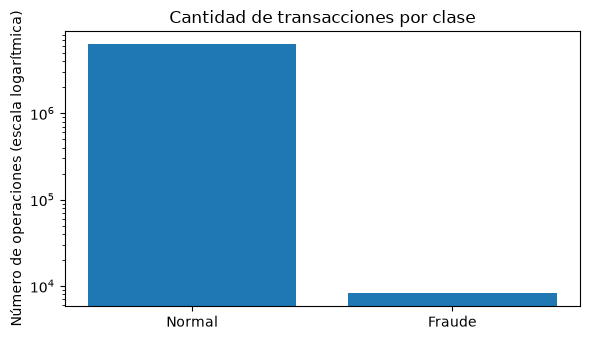

In [4]:
class_table = (
    df.groupBy("_label").count().orderBy("_label").toPandas()
)
if set(class_table["_label"]) != {0.0, 1.0}:
    raise ValueError("El conjunto de datos debe contener ambas clases (0 y 1).")
class_table["clase"] = class_table["_label"].map({0.0: "Normal", 1.0: "Fraude"})
prevalence = float(class_table.loc[class_table["_label"] == 1, "count"].iloc[0]) / N
print(class_table[["clase", "count"]].to_string(index=False))
print(f"Porcentaje de fraude: {prevalence:.4%}")
print(f"AUC-PR de un clasificador aleatorio (aprox.): {prevalence:.6f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(class_table["clase"], class_table["count"])
ax.set_yscale("log")
ax.set_title("Cantidad de transacciones por clase")
ax.set_ylabel("Número de operaciones (escala logarítmica)")
plt.tight_layout()
plt.savefig(OUT / "01_desbalance.png", dpi=140)
plt.show()


## 4. Análisis exploratorio (EDA)

### 4.1 ¿Qué caracteriza a las transacciones normales y fraudulentas?

Vamos a analizar **solo unas pocas variables financieras fáciles de explicar**: `amount` (importe), `oldbalanceOrg` (saldo previo del origen) y `oldbalanceDest` (saldo previo del destino). Mostramos media y mediana por clase.

> La media puede verse afectada por importes extremos. Por eso también mostramos la mediana.

In [5]:
eda_cols = [c for c in ["amount", "oldbalanceOrg", "oldbalanceDest"] if c in numeric_cols]
if not eda_cols:
    raise ValueError("No se encontraron las variables financieras esperadas para el análisis.")

eda_rows = []
for c in eda_cols:
    stats = (
        df.groupBy("_label")
        .agg(
            F.mean(c).alias("media"),
            F.expr(f"percentile_approx(`{c}`, 0.5, 1000)").alias("mediana")
        )
        .collect()
    )
    for r in stats:
        eda_rows.append({"variable": c, "clase": "Fraude" if r["_label"] == 1 else "Normal",
                         "media": r["media"], "mediana": r["mediana"]})
eda_table = pd.DataFrame(eda_rows)
print(eda_table.round(2).to_string(index=False))
eda_table.to_csv(OUT / "eda_importes.csv", index=False)


      variable  clase      media   mediana
        amount Fraude 1467967.30 438983.45
        amount Normal  178197.04  74519.99
 oldbalanceOrg Fraude 1649667.61 438224.60
 oldbalanceOrg Normal  832828.71  14069.00
oldbalanceDest Fraude 1080474.29 141736.75
oldbalanceDest Normal 1130182.48 158081.05


### 4.2 ¿En qué tipos de operación aparece fraude?

Calculamos la **tasa de fraude**, no solo el número de operaciones: `fraudes / operaciones totales` en cada tipo. El gráfico compara porcentajes y no requiere procesar millones de filas en pandas.

    type  operaciones  fraudes  tasa_fraude
CASH_OUT      2237500   4116.0     0.001840
 PAYMENT      2151495      0.0     0.000000
 CASH_IN      1399284      0.0     0.000000
TRANSFER       532909   4097.0     0.007688
   DEBIT        41432      0.0     0.000000


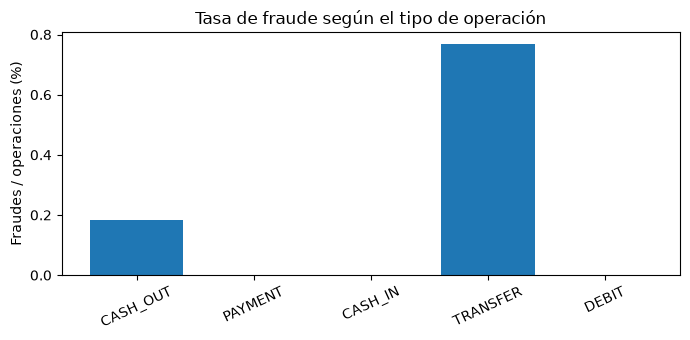

In [6]:
if "type" in df.columns:
    types = (
        df.groupBy("type")
        .agg(F.count("*").alias("operaciones"), F.sum("_label").alias("fraudes"))
        .withColumn("tasa_fraude", F.col("fraudes") / F.col("operaciones"))
        .orderBy(F.desc("operaciones"))
        .toPandas()
    )
    print(types.to_string(index=False))
    types.to_csv(OUT / "fraude_por_tipo.csv", index=False)

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(types["type"].astype(str), types["tasa_fraude"] * 100)
    ax.set_title("Tasa de fraude según el tipo de operación")
    ax.set_ylabel("Fraudes / operaciones (%)")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.savefig(OUT / "02_fraude_por_tipo.png", dpi=140)
    plt.show()
else:
    print("El dataset no incluye 'type'. Se omite este análisis.")


### 4.3 Correlaciones: una comprobación pequeña

Una correlación cercana a `1` o `-1` indica una relación lineal fuerte entre dos números. **No implica causalidad**, ni demuestra que una variable cause fraude.

Para no llenar el trabajo de matrices difíciles de leer, mostramos solamente las parejas de variables financieras más relacionadas. Esto ayuda a detectar redundancias en los datos.

In [7]:
finance_cols = [
    c for c in ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
    if c in numeric_cols
]
correlations = []
for i, a in enumerate(finance_cols):
    for b in finance_cols[i+1:]:
        r = df.stat.corr(a, b)
        correlations.append({"variable_1": a, "variable_2": b, "pearson": r})

corr_table = pd.DataFrame(correlations)
if not corr_table.empty:
    corr_table["abs_pearson"] = corr_table["pearson"].abs()
    corr_table = corr_table.sort_values("abs_pearson", ascending=False)
    print(corr_table.head(8).round(4).to_string(index=False))
    corr_table.to_csv(OUT / "correlaciones_financieras.csv", index=False)
else:
    print("No hay suficientes variables financieras para calcular correlaciones.")


    variable_1     variable_2  pearson  abs_pearson
 oldbalanceOrg newbalanceOrig   0.9988       0.9988
oldbalanceDest newbalanceDest   0.9766       0.9766
        amount newbalanceDest   0.4593       0.4593
        amount oldbalanceDest   0.2941       0.2941
newbalanceOrig oldbalanceDest   0.0678       0.0678
 oldbalanceOrg oldbalanceDest   0.0662       0.0662
 oldbalanceOrg newbalanceDest   0.0420       0.0420
newbalanceOrig newbalanceDest   0.0418       0.0418


## 5. Preparación de los datos y elección de variables

### 5.1 Evitar fugas de información (*data leakage*)

**Pregunta clave:** ¿tenemos esa variable *antes* de decidir si la transacción es fraude?

- **Modelo operativo principal:** importe, saldos **previos**, tipo de operación, tiempo e indicador de comercio si existe.
- **Variables potencialmente problemáticas:** `newbalanceOrig`, `newbalanceDest`, `errorBalanceOrig`, `errorBalanceDest` y `isFlaggedFraud`. Pueden reflejar información posterior a la transacción o reglas previas de detección.
- **Identificadores:** `nameOrig` y `nameDest` se excluyen de este modelo básico; pueden tener cardinalidad muy elevada y complicar la interpretación.

No afirmamos que todas las variables anteriores sean fugas demostradas: la disponibilidad temporal debe justificarse con la documentación de los datos.

In [8]:
# Variables que utilizamos en el modelo principal.
safe_candidates = [
    "amount", "oldbalanceOrg", "oldbalanceDest",
    "step", "day_of_sim", "hour_of_day", "is_merchant_dest"
]
NUM = [c for c in safe_candidates if c in numeric_cols]
CAT = [c for c in ["type"] if c in df.columns]

# Evitar introducir el mismo tiempo expresado de dos maneras.
if all(c in NUM for c in ("step", "day_of_sim", "hour_of_day")):
    NUM.remove("step")

# SOLO para la comparación adicional: se excluyen del modelo principal.
POST = [c for c in ["newbalanceOrig", "newbalanceDest"] if c in numeric_cols]
if not NUM:
    raise ValueError("No hay variables numéricas admitidas para entrenar.")

print("Numéricas del modelo operativo:", NUM)
print("Categóricas del modelo operativo:", CAT)
print("Saldos posteriores (SOLO experimento):", POST)


Numéricas del modelo operativo: ['amount', 'oldbalanceOrg', 'oldbalanceDest', 'step', 'is_merchant_dest']
Categóricas del modelo operativo: ['type']
Saldos posteriores (SOLO experimento): ['newbalanceOrig', 'newbalanceDest']


### 5.2 División en entrenamiento, validación y test

Utilizamos **70 % para entrenar**, **15 % para validar** (comparar y ajustar) y **15 % para test** (evaluación final).

Los modelos aprenden con *train*. Con *validación* elegimos el mejor y ajustamos el umbral. **Test no se utiliza hasta el final.**

**Limitación:** aquí usamos particiones aleatorias como en el notebook original. Si quisiéramos simular despliegue real, sería preferible una separación temporal y vigilar transacciones del mismo cliente en varios conjuntos.

In [9]:
# Preparar los datos
all_needed = list(dict.fromkeys(NUM + POST + CAT))

work = df.select("_label", *all_needed).withColumnRenamed(
    "_label", "label"
)

# Preparar variables numéricas
for c in NUM + POST:
    work = work.withColumn(c, F.col(c).cast("double"))
    work = work.withColumn(
        c, F.when(F.isnan(F.col(c)), None).otherwise(F.col(c))
    )

# Preparar variables categóricas
for c in CAT:
    work = work.withColumn(
        c,
        F.coalesce(F.col(c).cast("string"), F.lit("__MISSING__"))
    )

# Dividir en entrenamiento (70%), validación (15%) y test (15%)
train, val, test = work.randomSplit(
    [0.70, 0.15, 0.15],
    seed=SEED
)

# Comprobar los conjuntos
for name, subset in [
    ("Entrenamiento", train),
    ("Validación", val),
    ("Test", test)
]:
    clases = {
        int(r["label"]): int(r["count"])
        for r in subset.groupBy("label").count().collect()
    }

    if 0 not in clases or 1 not in clases:
        raise ValueError(f"Falta alguna clase en {name}")

    total = sum(clases.values())

    print(
        f"{name}: {total:,} operaciones | "
        f"Normales: {clases[0]:,} | "
        f"Fraudes: {clases[1]:,}"
    )

Entrenamiento: 4,453,343 operaciones | Normales: 4,447,605 | Fraudes: 5,738
Validación: 953,205 operaciones | Normales: 951,982 | Fraudes: 1,223
Test: 956,072 operaciones | Normales: 954,820 | Fraudes: 1,252


### 5.3 Pipeline de preprocesamiento

Un *pipeline* es una secuencia automática de pasos. En este caso:

1. Sustituir números ausentes por la **mediana** aprendida en entrenamiento.
2. Convertir `type` (texto) en columnas numéricas mediante `StringIndexer` y `OneHotEncoder`.
3. Unir las columnas en el vector `features` que necesitan los algoritmos de MLlib.

**Ventaja:** cada modelo aplica los mismos pasos, y no calculamos medianas o categorías con los datos de validación o test.

In [10]:
def make_preprocessing(numeric_features, categorical_features):
    """Crea el mismo preprocesamiento para cualquier algoritmo."""
    steps = []
    output_num = [f"{c}_imp" for c in numeric_features]
    steps.append(Imputer(inputCols=numeric_features, outputCols=output_num, strategy="median"))

    output_cat = []
    for c in categorical_features:
        steps.append(StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep"))
        steps.append(OneHotEncoder(inputCols=[f"{c}_idx"],
                                   outputCols=[f"{c}_ohe"], handleInvalid="keep"))
        output_cat.append(f"{c}_ohe")

    steps.append(VectorAssembler(inputCols=output_num + output_cat,
                                 outputCol="features", handleInvalid="error"))
    return steps

pr_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction",
                                        metricName="areaUnderPR")
roc_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction",
                                         metricName="areaUnderROC")

def evaluate_predictions(pred):
    """Calcula las métricas de fraude y la matriz de confusión (sin pandas masivo)."""
    pairs = pred.groupBy("label", "prediction").count().collect()
    cm = {(int(r["label"]), int(r["prediction"])): int(r["count"]) for r in pairs}
    tn = cm.get((0, 0), 0)
    fp = cm.get((0, 1), 0)
    fn = cm.get((1, 0), 0)
    tp = cm.get((1, 1), 0)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "auc_pr": float(pr_eval.evaluate(pred)),
        "auc_roc": float(roc_eval.evaluate(pred)),
        "precision": precision, "recall": recall, "f1": f1,
        "tn": tn, "fp": fp, "fn": fn, "tp": tp
    }

print("Pipeline y evaluación preparados.")


Pipeline y evaluación preparados.


## 6. Entrenamiento y comparación de modelos

Entrenamos los **mismos datos** con tres algoritmos:

| Modelo | Explicación sencilla |
|---|---|
| Regresión logística | Referencia inicial: aprende una combinación de las variables |
| Random Forest | Combina muchos árboles de decisión |
| Gradient-Boosted Trees (GBT) | Construye árboles sucesivos para mejorar los errores |

Los tres usan las mismas variables y el mismo pipeline. La comparación se hace sobre **validación**, no sobre test.

In [11]:
lr_params = {"labelCol": "label", "featuresCol": "features",
             "maxIter": 50, "regParam": 0.05, "standardization": True}

algorithms = {
    "RegresionLogistica": LogisticRegression(**lr_params),
    "RandomForest": RandomForestClassifier(labelCol="label", featuresCol="features",
                                           numTrees=60, maxDepth=7, seed=SEED),
    "GBT": GBTClassifier(labelCol="label", featuresCol="features",
                         maxIter=35, maxDepth=5, seed=SEED),
}

trained_models = {}
model_results = []

for name, algorithm in algorithms.items():
    print("Entrenando:", name)
    t0 = time.perf_counter()
    pipeline = Pipeline(stages=make_preprocessing(NUM, CAT) + [algorithm])
    model = pipeline.fit(train)
    metrics = evaluate_predictions(model.transform(val))
    trained_models[name] = model
    model_results.append({"modelo": name, "segundos": round(time.perf_counter()-t0, 1), **metrics})
    print(f"  AUC-PR={metrics['auc_pr']:.4f} | Recall={metrics['recall']:.4f} | "
          f"Precision={metrics['precision']:.4f}")

print("\nSe han entrenado los tres modelos.")


Entrenando: RegresionLogistica
  AUC-PR=0.0182 | Recall=0.0000 | Precision=0.0000
Entrenando: RandomForest
  AUC-PR=0.6748 | Recall=0.2927 | Precision=0.9972
Entrenando: GBT
  AUC-PR=0.7317 | Recall=0.5765 | Precision=0.9264

Se han entrenado los tres modelos.


## 7. Optimización de hiperparámetros: Random Forest y GBT

Como Random Forest y GBT obtuvieron mejores resultados iniciales que la regresión logística, optimizamos estos dos modelos. La regresión logística se mantiene como referencia.

### Hiperparámetros que vamos a optimizar

- **Random Forest:**
  - `numTrees`: 40 y 60 árboles.
  - `maxDepth`: profundidades 5 y 7.

- **GBT:**
  - `maxIter`: 20 y 35 iteraciones.
  - `maxDepth`: profundidades 3 y 5.

En total se prueban **4 combinaciones por modelo (8 en total)**.

### Método de optimización

Utilizamos `TrainValidationSplit` para encontrar la mejor combinación de hiperparámetros.

1. Se utiliza el conjunto de entrenamiento (`train`).
2. Internamente se divide en un 80 % para entrenar y un 20 % para validar.
3. Se evalúan las combinaciones utilizando la métrica **AUC-PR**.
4. Se selecciona la combinación con mayor AUC-PR.
5. El mejor modelo se evalúa sobre el conjunto de validación externo (`val`).

### Consideraciones de rendimiento

Debido al gran tamaño del dataset (más de 6 millones de transacciones), limitamos el número de combinaciones para reducir el tiempo de ejecución.

Además, utilizamos `parallelism=1` para entrenar las configuraciones secuencialmente y evitar un consumo excesivo de memoria.

In [12]:
# 7. OPTIMIZACIÓN DE RANDOM FOREST Y GBT
# La regresión logística se mantiene como referencia sin optimizar.

rf_tuned = RandomForestClassifier(
    labelCol="label", featuresCol="features", seed=SEED
)
gbt_tuned = GBTClassifier(
    labelCol="label", featuresCol="features", seed=SEED
)

# Cuatro combinaciones de hiperparámetros para cada algoritmo.
searches = {
    "RandomForest": (
        rf_tuned,
        [(rf_tuned.numTrees, [40, 60]),
         (rf_tuned.maxDepth, [5, 7])]
    ),
    "GBT": (
        gbt_tuned,
        [(gbt_tuned.maxIter, [20, 35]),
         (gbt_tuned.maxDepth, [3, 5])]
    ),
}

# Evitar duplicados si ejecutamos esta celda más de una vez.
model_results = [r for r in model_results
                 if r["modelo"] not in ("RandomForest_optimizado", "GBT_optimizado")]

for name, (algorithm, parameters) in searches.items():
    grid_builder = ParamGridBuilder()
    for parameter, values in parameters:
        grid_builder.addGrid(parameter, values)
    param_grid = grid_builder.build()

    tuner = TrainValidationSplit(
        estimator=Pipeline(stages=make_preprocessing(NUM, CAT) + [algorithm]),
        estimatorParamMaps=param_grid,
        evaluator=pr_eval,           # Maximizar AUC-PR
        trainRatio=0.80,            # División interna del conjunto train
        seed=SEED,
        parallelism=1               # Limita el consumo simultáneo de memoria
    )

    print(f"\nOptimizando {name}: {len(param_grid)} combinaciones")
    t0 = time.perf_counter()
    tuned = tuner.fit(train)
    opt_seconds = round(time.perf_counter() - t0, 1)

    best_grid_idx = int(np.argmax(tuned.validationMetrics))
    print("Mejor combinación (validación interna):")
    for parameter, value in param_grid[best_grid_idx].items():
        print(" -", parameter.name, "=", value)
    print("AUC-PR validación interna:",
          round(float(tuned.validationMetrics[best_grid_idx]), 5))

    # Comparación externa sobre val, que no participa en esta búsqueda interna.
    best_name = name + "_optimizado"
    trained_models[best_name] = tuned.bestModel
    metrics_tuned = evaluate_predictions(tuned.bestModel.transform(val))
    model_results.append({"modelo": best_name, "segundos": opt_seconds,
                          **metrics_tuned})
    print(f"AUC-PR en validación externa: {metrics_tuned['auc_pr']:.5f}")

print("\nOptimización de Random Forest y GBT finalizada.")



Optimizando RandomForest: 4 combinaciones
Mejor combinación (validación interna):
 - numTrees = 40
 - maxDepth = 7
AUC-PR validación interna: 0.68479
AUC-PR en validación externa: 0.68286

Optimizando GBT: 4 combinaciones
Mejor combinación (validación interna):
 - maxIter = 35
 - maxDepth = 5
AUC-PR validación interna: 0.71986
AUC-PR en validación externa: 0.73175

Optimización de Random Forest y GBT finalizada.


### 7.1 Tabla única de resultados de validación

**Cómo leerla:**

- **AUC-PR (principal):** cuanto mayor, mejor para separar fraudes cuando son raros.
- **Recall:** qué parte de los fraudes reales identificamos.
- **Precision:** de las alarmas de fraude, cuántas son correctas.
- **F1:** equilibra precisión y recall. Los tres valores dependen del umbral actual, inicialmente 0,5.

No escogeremos el modelo por *accuracy*, ya que el fraude es muy minoritario.

In [13]:
results = pd.DataFrame(model_results).sort_values("auc_pr", ascending=False).reset_index(drop=True)
columns_to_show = ["modelo", "auc_pr", "auc_roc", "precision", "recall", "f1", "segundos"]
print(results[columns_to_show].round(4).to_string(index=False))
results.to_csv(OUT / "comparacion_validacion.csv", index=False)


                 modelo  auc_pr  auc_roc  precision  recall     f1  segundos
                    GBT  0.7317   0.9914     0.9264  0.5765 0.7107     927.9
         GBT_optimizado  0.7317   0.9914     0.9264  0.5765 0.7107    1667.2
RandomForest_optimizado  0.6829   0.9751     0.9972  0.2862 0.4447     718.0
           RandomForest  0.6748   0.9694     0.9972  0.2927 0.4526     708.1
     RegresionLogistica  0.0182   0.9142     0.0000  0.0000 0.0000     293.0


## 8. Comparación adicional: ¿qué ocurre si usamos los saldos posteriores?

Este apartado recupera el objetivo de **comparación de variables** del notebook original, pero lo plantea de forma controlada:

- Mismo algoritmo: regresión logística sin optimizar.
- Mismos conjuntos de entrenamiento y validación.
- **Dos grupos de variables:** las operativas frente a operativas **más saldos posteriores**.

Si el modelo con saldos posteriores mejora, esto **no prueba** que eliminar correlaciones empeore el modelo. Lo que cambia es la información disponible. Por tanto, este modelo retrospectivo **no compite para ser desplegado**.

Puede desactivarse cambiando `COMPARAR_SALDOS_POSTERIORES = False` en la configuración.

In [14]:
comparison_features = None
if COMPARAR_SALDOS_POSTERIORES and POST:
    print("Comparando variables anteriores frente a anteriores + posteriores...")
    retrospective = Pipeline(
        stages=make_preprocessing(NUM + POST, CAT) + [LogisticRegression(**lr_params)]
    ).fit(train)
    retrospective_metrics = evaluate_predictions(retrospective.transform(val))
    operational_metrics = next(r for r in model_results if r["modelo"] == "RegresionLogistica")

    comparison_features = pd.DataFrame([
        {"variante": "Operativo (antes)", "n_variables": len(NUM)+len(CAT),
         "auc_pr": operational_metrics["auc_pr"], "precision": operational_metrics["precision"],
         "recall": operational_metrics["recall"]},
        {"variante": "Retrospectivo (antes + después)", "n_variables": len(NUM)+len(POST)+len(CAT),
         "auc_pr": retrospective_metrics["auc_pr"], "precision": retrospective_metrics["precision"],
         "recall": retrospective_metrics["recall"]},
    ])
    print(comparison_features.round(4).to_string(index=False))
    comparison_features.to_csv(OUT / "comparacion_variables.csv", index=False)
    print("Nota: la comparación explora DISPONIBILIDAD TEMPORAL, no causalidad ni solo correlación.")
else:
    print("Experimento opcional omitido. No afecta a la selección del modelo operativo.")


Comparando variables anteriores frente a anteriores + posteriores...
                       variante  n_variables  auc_pr  precision  recall
              Operativo (antes)            6  0.0182        0.0     0.0
Retrospectivo (antes + después)            8  0.0182        0.0     0.0
Nota: la comparación explora DISPONIBILIDAD TEMPORAL, no causalidad ni solo correlación.


## 9. Elegir el mejor modelo y ajustar el umbral

### 9.1 Seleccionar el algoritmo

Seleccionamos el modelo con **mayor AUC-PR en validación externa**. La regresión logística optimizada **sí participa** en esta elección.

In [15]:
winner = str(results.iloc[0]["modelo"])
best_model = tuned.bestModel if winner == "LR_optimizada" else trained_models[winner]
print("Modelo seleccionado:", winner)
print("AUC-PR de validación:", round(float(results.iloc[0]["auc_pr"]), 5))


Modelo seleccionado: GBT
AUC-PR de validación: 0.73175


### 9.2 Elegir cuándo activar una alerta

Por defecto muchos clasificadores predicen fraude si la probabilidad es al menos `0.5`. Pero con una clase tan rara ese valor puede no ser el mejor.

Probamos distintos **umbrales en validación**, calculamos precisión, recall y F1, y elegimos el que maximiza **F1**. Este criterio es ilustrativo: en una aplicación bancaria real también habría que definir el coste de las falsas alarmas y de los fraudes no detectados.

In [16]:
score_val = (
    best_model.transform(val)
    .select("label", vector_to_array("probability")[1].alias("score"))
    .persist(StorageLevel.MEMORY_AND_DISK)
)
thresholds = [0.001, 0.005, 0.01, 0.03, 0.05, 0.10, 0.20,
              0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]

# Un único agregado distribuido: no recorrer millones de filas 15 veces.
exprs = [F.sum(F.col("label")).alias("total_fraudes")]
for i, threshold in enumerate(thresholds):
    exprs.extend([
        F.sum(F.when((F.col("label") == 1) & (F.col("score") >= threshold), 1)
              .otherwise(0)).alias(f"tp_{i}"),
        F.sum(F.when((F.col("label") == 0) & (F.col("score") >= threshold), 1)
              .otherwise(0)).alias(f"fp_{i}")
    ])
counts = score_val.agg(*exprs).first().asDict()
total_frauds_val = int(counts["total_fraudes"])
threshold_rows = []
for i, threshold in enumerate(thresholds):
    tp = int(counts[f"tp_{i}"] or 0)
    fp = int(counts[f"fp_{i}"] or 0)
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / total_frauds_val if total_frauds_val else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    threshold_rows.append({"umbral": threshold, "precision": prec, "recall": rec,
                           "f1": f1, "fraudes_detectados": tp, "falsas_alarmas": fp})

threshold_table = pd.DataFrame(threshold_rows).sort_values("f1", ascending=False)
chosen_threshold = float(threshold_table.iloc[0]["umbral"])
print(threshold_table.round(4).to_string(index=False))
print("Umbral elegido (F1 máximo):", chosen_threshold)
threshold_table.to_csv(OUT / "umbrales_validacion.csv", index=False)
score_val.unpersist()


 umbral  precision  recall     f1  fraudes_detectados  falsas_alarmas
  0.300     0.8465  0.6672 0.7462                 816             148
  0.200     0.7994  0.6942 0.7431                 849             213
  0.400     0.8693  0.6419 0.7385                 785             118
  0.500     0.9264  0.5765 0.7107                 705              56
  0.600     0.9684  0.4505 0.6150                 551              18
  0.100     0.5194  0.7351 0.6087                 899             832
  0.700     0.9732  0.4154 0.5822                 508              14
  0.050     0.3920  0.7612 0.5175                 931            1444
  0.800     0.9727  0.3491 0.5138                 427              12
  0.900     0.9747  0.3156 0.4768                 386              10
  0.950     1.0000  0.2339 0.3791                 286               0
  0.030     0.0256  0.9379 0.0499                1147           43614
  0.005     0.0013  1.0000 0.0026                1223          951982
  0.010     0.0013  

DataFrame[label: double, score: double]

## 10. Resultados finales: evaluación en test

**Esta es la única parte donde se consulta test.** Ya hemos elegido algoritmo, hiperparámetros y umbral utilizando únicamente entrenamiento y validación.

Además de AUC-PR, veremos **TP, FP, FN y TN**:

- **TP:** fraude bien detectado.
- **FP:** transacción normal que genera una falsa alarma.
- **FN:** fraude no detectado.
- **TN:** transacción normal correctamente identificada.

El gráfico siguiente es una matriz de confusión: las **filas son la realidad** y las **columnas son las predicciones**.

modelo  umbral  auc_pr  auc_roc  precision  recall      f1
   GBT     0.3 0.75468  0.99232    0.87437 0.69489 0.77437
Fraudes detectados: 870 | Fraudes no detectados: 382
Falsas alarmas: 125 | Normales bien clasificadas: 954695


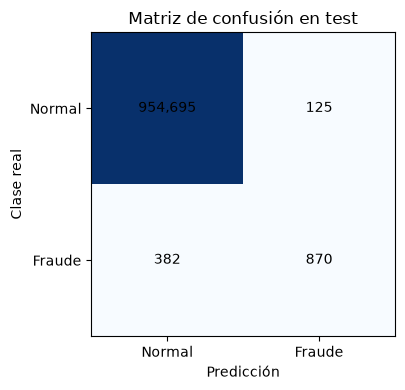

DataFrame[label: double, amount: double, oldbalanceOrg: double, oldbalanceDest: double, step: double, is_merchant_dest: double, newbalanceOrig: double, newbalanceDest: double, type: string, amount_imp: double, oldbalanceOrg_imp: double, oldbalanceDest_imp: double, step_imp: double, is_merchant_dest_imp: double, type_idx: double, type_ohe: vector, features: vector, rawPrediction: vector, probability: vector, prediction: double]

In [17]:
score_test = best_model.transform(test)
pred_test = score_test.withColumn(
    "prediction",
    F.when(vector_to_array("probability")[1] >= chosen_threshold, 1.0).otherwise(0.0)
).persist(StorageLevel.MEMORY_AND_DISK)

final = evaluate_predictions(pred_test)
summary = pd.DataFrame([{ "modelo": winner, "umbral": chosen_threshold, **final }])
print(summary[["modelo", "umbral", "auc_pr", "auc_roc", "precision", "recall", "f1"]]
      .round(5).to_string(index=False))
print(f"Fraudes detectados: {final['tp']} | Fraudes no detectados: {final['fn']}")
print(f"Falsas alarmas: {final['fp']} | Normales bien clasificadas: {final['tn']}")
summary.to_csv(OUT / "metricas_test.csv", index=False)

conf_matrix = np.array([[final["tn"], final["fp"]],
                        [final["fn"], final["tp"]]])
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.imshow(conf_matrix, cmap="Blues")
for row in range(2):
    for col in range(2):
        ax.text(col, row, f"{conf_matrix[row, col]:,}",
                ha="center", va="center", fontsize=10)
ax.set_xticks([0, 1], ["Normal", "Fraude"])
ax.set_yticks([0, 1], ["Normal", "Fraude"])
ax.set_xlabel("Predicción")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión en test")
plt.tight_layout()
plt.savefig(OUT / "03_matriz_confusion_test.png", dpi=140)
plt.show()
pred_test.unpersist()


## 11. Interpretación y conclusiones

### 11.1 ¿Qué variables utiliza Random Forest?

Aunque Random Forest no haya sido el ganador, nos permite inspeccionar qué características le resultan útiles. Mostramos únicamente sus **8 características más importantes** en forma de tabla, sin otro gráfico.

> La importancia es una medida del modelo, **no una prueba de causalidad**. Las variables codificadas (`type_ohe_...`) son categorías de `type`.

In [18]:
rf_model = trained_models["RandomForest"]
rf_importance = rf_model.stages[-1].featureImportances.toArray()
feature_meta = rf_model.transform(val.limit(1)).schema["features"].metadata
attrs = feature_meta.get("ml_attr", {}).get("attrs", {})
feature_names = {
    int(item["idx"]): item["name"]
    for attr_group in attrs.values() for item in attr_group
}
importance_table = pd.DataFrame([
    {"variable": feature_names.get(i, f"feature_{i}"), "importancia": float(value)}
    for i, value in enumerate(rf_importance)
]).sort_values("importancia", ascending=False)
print(importance_table.head(8).round(4).to_string(index=False))
importance_table.to_csv(OUT / "importancia_variables_rf.csv", index=False)


            variable  importancia
   oldbalanceOrg_imp       0.4296
          amount_imp       0.2140
  oldbalanceDest_imp       0.1814
   type_ohe_TRANSFER       0.0595
   type_ohe_CASH_OUT       0.0550
            step_imp       0.0469
    type_ohe_CASH_IN       0.0128
is_merchant_dest_imp       0.0004


### 11.2 Conclusiones que podemos defender

Este bloque imprime un resumen basado **en los resultados realmente calculados**. No sustituye la explicación de la memoria: hay que comentar si compensa el número de falsas alarmas y recordar las limitaciones del conjunto de datos.

In [19]:
print("=== CONCLUSIONES AUTOMÁTICAS ===")
print(f"El conjunto contiene {N:,} transacciones; el fraude representa {prevalence:.4%}.")
print(f"Mejor modelo operativo en validación (AUC-PR): {winner}.")
print(f"Umbral seleccionado sin usar test: {chosen_threshold}.")
print(f"En test: AUC-PR={final['auc_pr']:.4f}, precisión={final['precision']:.4f}, "
      f"recall={final['recall']:.4f}, F1={final['f1']:.4f}.")
print(f"Detecta {final['tp']} fraudes; omite {final['fn']} y genera {final['fp']} falsas alarmas.")
if comparison_features is not None:
    print("La comparación con saldos posteriores es EXPLORATORIA y no valida su uso en tiempo real.")
print("Limitaciones: datos históricos/simulados según la fuente, partición aleatoria, "
      "posibles cambios temporales y costes reales de los errores no modelados.")


=== CONCLUSIONES AUTOMÁTICAS ===
El conjunto contiene 6,362,620 transacciones; el fraude representa 0.1291%.
Mejor modelo operativo en validación (AUC-PR): GBT.
Umbral seleccionado sin usar test: 0.3.
En test: AUC-PR=0.7547, precisión=0.8744, recall=0.6949, F1=0.7744.
Detecta 870 fraudes; omite 382 y genera 125 falsas alarmas.
La comparación con saldos posteriores es EXPLORATORIA y no valida su uso en tiempo real.
Limitaciones: datos históricos/simulados según la fuente, partición aleatoria, posibles cambios temporales y costes reales de los errores no modelados.


### 11.3 Exportar resultados y modelo

Las tablas y los tres gráficos ya se han guardado en `resultados/`. También guardamos un pequeño JSON y, si está activado, el modelo Spark entrenado.

El profesor solicita un proyecto reproducible: junto a este notebook se entrega un **script `.py`** que ejecuta el mismo flujo y un **`README.md`** que indica cómo ejecutarlo.

In [20]:
result_info = {
    "filas": int(N), "fraude_porcentaje": 100 * float(prevalence),
    "modelo": winner, "umbral": chosen_threshold,
    "metricas_test": {k: float(v) if isinstance(v, (np.floating, float)) else int(v)
                      for k, v in final.items()},
    "variables_operativas": NUM + CAT,
    "variables_retrospectivas_solo_experimento": POST,
}
with open(OUT / "resultados_finales.json", "w", encoding="utf-8") as fh:
    json.dump(result_info, fh, ensure_ascii=False, indent=2)
print("Resumen guardado:", OUT / "resultados_finales.json")

if GUARDAR_MODELO:
    model_path = OUT / "modelo_final_spark"
    try:
        best_model.write().overwrite().save(str(model_path.resolve()))
        print("Modelo guardado en:", model_path.resolve())
    except Exception as exc:
        print("No se ha podido exportar el modelo Spark:", str(exc)[:300])
        print("Las métricas y tablas sí están guardadas; verifica Spark/Hadoop en tu entorno.")


Resumen guardado: resultados\resultados_finales.json
No se ha podido exportar el modelo Spark: An error occurred while calling o10290.save.
: org.apache.spark.SparkException: Job aborted.
	at org.apache.spark.internal.io.SparkHadoopWriter$.write(SparkHadoopWriter.scala:106)
	at org.apache.spark.rdd.PairRDDFunctions.$anonfun$saveAsHadoopDataset$1(PairRDDFunctions.scala:1091)
	at scala.runti
Las métricas y tablas sí están guardadas; verifica Spark/Hadoop en tu entorno.


### 11.4 Spark, RDDs y limpieza

Para documentar el trabajo distribuido mostramos qué motor y cuántas particiones se han utilizado. Spark trabaja normalmente con **DataFrames**, como en todo el análisis. Los RDDs son una abstracción de nivel inferior que también forma parte de MLlib/Spark.

Se incluye un ejemplo **opcional** de transformación RDD de las etiquetas. Se deja desactivado por defecto porque en algunos equipos Windows los procesos Python de los RDD dan problemas; puede activarse cuando el entorno de PySpark esté bien configurado.

In [21]:
print("Spark master:", spark.sparkContext.master)
print("Particiones de train:", train.rdd.getNumPartitions())
print("Particiones de val:", val.rdd.getNumPartitions())

EJECUTAR_EJEMPLO_RDD = False
if EJECUTAR_EJEMPLO_RDD:
    # Distribución de las clases usando operaciones RDD (como contraste con DataFrame).
    rdd_counts = (
        train.select("label").rdd
        .map(lambda row: (int(row["label"]), 1))
        .reduceByKey(lambda a, b: a + b)
        .collect()
    )
    print("Recuento de clases calculado con RDD:", sorted(rdd_counts))

train.unpersist()
val.unpersist()
test.unpersist()
print("Análisis finalizado. Revisa la carpeta:", OUT.resolve())


Spark master: local[2]
Particiones de train: 5
Particiones de val: 5
Análisis finalizado. Revisa la carpeta: C:\Users\murad\OneDrive - Universidade da Coruña\4 Curso\AAGE\AAGE_P1_fraude_pack\resultados
